# GPU cloud prices: starter notebook

What does an H100, H200 or B200 hour actually cost across cloud providers right now, and how much do prices move day to day?

This notebook loads the [GPU Cloud Rental Prices](https://www.kaggle.com/datasets/hundredthrun/gpu-cloud-rental-prices) dataset (sourced list prices from 25 providers, normalized to USD per GPU-hour, re-checked daily) and answers a few buyer questions:

1. Cheapest on-demand price per GPU model
2. Spread between the cheapest and most expensive provider
3. Spot vs on-demand gap
4. Daily median price history
5. Which providers changed prices, and by how much

Runs on Kaggle, or anywhere with pandas: outside Kaggle it reads the same files from the [Hugging Face mirror](https://huggingface.co/datasets/hundredthrun/gpu-cloud-prices). [Open in Colab](https://colab.research.google.com/github/hundredthrun/gpu-cloud-prices/blob/main/notebooks/gpu-cloud-prices-starter.ipynb).

Live tables, calculators and price history charts: [Hundredth Run compute desk](https://hundredthrun-compute-desk.pages.dev). Every row links to its source page; check `date_checked` before you buy.

In [1]:
import glob, os
import pandas as pd
import matplotlib.pyplot as plt

HF = 'https://huggingface.co/datasets/hundredthrun/gpu-cloud-prices/resolve/main/'

def find(name):
    # Kaggle input folder first, then a local copy, then the Hugging Face mirror.
    hits = glob.glob(f'/kaggle/input/**/{name}', recursive=True) or glob.glob(name)
    return hits[0] if hits else HF + name

prices = pd.read_csv(find('gpu_prices.csv'))
history = pd.read_csv(find('gpu_price_history.csv'), parse_dates=['date'])
rows = pd.read_csv(find('gpu_price_rows_daily.csv'))
print(prices.shape, history.shape, rows.shape)
prices.head()

(211, 18) (50, 7) (1055, 19)


,provider,gpu,variant,gpus_per_unit,price_usd_per_gpu_hr,price_type,term,region,billing_unit,price_as_listed,derivation,availability_note,lead_time_class,source_url,date_checked,fetch_method,confidence,notes
0,Latitude.sh,H100,80GB,1.0,1.68,on_demand,none,not itemized,"per hour, 1x H100 server",Starting at $1.68/hr,NaN,Bare metal,unknown,https://www.latitude.sh/pricing,2026-11-01,manual,medium,'Starting at' price. Read by hand from the pag...
1,Voltage Park,H100,HGX,1.0,1.99,on_demand,none,not stated,per GPU-hour,starting at $1.99 per FAQ,NaN,"Page: self-serve, up within 15 mins, no minimu...",instant_self_serve,https://www.voltagepark.com/pricing,2026-11-08,html_static,low,Only a FAQ sentence gives a price ('starting a...
2,Hyperstack,H100,NaN,1.0,2.50,on_demand,none,not stated,per GPU-hour (billed per minute),$2.50/hr,NaN,NaN,unknown,https://www.hyperstack.cloud/gpu-pricing,2026-11-08,html_static,high,NaN
3,Hyperstack,H100,NVL,1.0,2.60,on_demand,none,not stated,per GPU-hour (billed per minute),$2.60/hr,NaN,NaN,unknown,https://www.hyperstack.cloud/gpu-pricing,2026-11-08,html_static,high,NaN
4,Massed Compute,H100,80GB,1.0,2.73,on_demand,none,not stated,"per instance-hour, divided by GPUs",$2.73/hr for 1x,2.73 / 1,NaN,instant_self_serve,https://www.massedcompute.com/pricing/,2026-11-08,html_static,medium,Page does not state region or availability. Pr...


## 1. Cheapest on-demand price per GPU

In [2]:
od = prices[(prices.price_type == 'on_demand') & prices.price_usd_per_gpu_hr.notna()]
idx = od.groupby('gpu').price_usd_per_gpu_hr.idxmin()
cheapest = od.loc[idx, ['gpu', 'provider', 'price_usd_per_gpu_hr', 'confidence', 'date_checked', 'source_url']]
cheapest.sort_values('price_usd_per_gpu_hr').reset_index(drop=True)

,gpu,provider,price_usd_per_gpu_hr,confidence,date_checked,source_url
0,L40S,Massed Compute,0.9700,medium,2026-11-08,https://www.massedcompute.com/pricing/
1,A100,Civo,1.0900,high,2026-11-08,https://www.civo.com/pricing
2,H100,Latitude.sh,1.6800,medium,2026-11-01,https://www.latitude.sh/pricing
3,MI300X,Crusoe,3.4500,medium,2026-11-08,https://www.crusoe.ai/cloud/pricing
4,H200,Civo,3.4900,high,2026-11-08,https://www.civo.com/pricing
5,B200,Massed Compute,5.4325,medium,2026-11-08,https://www.massedcompute.com/pricing/
6,B300,Hyperstack,7.4000,high,2026-11-08,https://www.hyperstack.cloud/gpu-pricing
7,MI355X,Oracle Cloud (OCI),8.6000,high,2026-11-08,https://www.oracle.com/cloud/price-list/
8,GB200,CoreWeave,10.5000,high,2026-11-08,https://www.coreweave.com/pricing
9,GB300,Verda,13.4400,high,2026-11-08,https://verda.com/pricing


## 2. Provider spread per GPU (on-demand)

The same GPU can cost several times more depending on where you rent it.

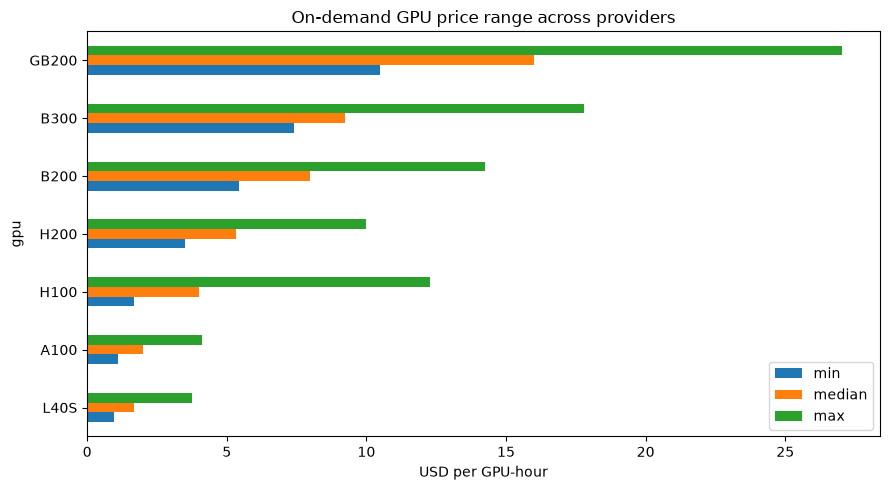

,min,median,max,count,max_over_min
gpu,,,,,
L40S,0.9700,1.695,3.7664,12,3.88
A100,1.0900,1.990,4.0963,25,3.76
H100,1.6800,3.990,12.2900,28,7.32
H200,3.4900,5.345,10.0000,12,2.87
B200,5.4325,7.990,14.2416,13,2.62
B300,7.4000,9.245,17.8020,8,2.41
GB200,10.5000,16.000,27.0400,3,2.58


In [3]:
spread = od.groupby('gpu').price_usd_per_gpu_hr.agg(['min', 'median', 'max', 'count'])
spread['max_over_min'] = (spread['max'] / spread['min']).round(2)
spread = spread[spread['count'] >= 3].sort_values('median')
ax = spread[['min', 'median', 'max']].plot.barh(figsize=(9, 5))
ax.set_xlabel('USD per GPU-hour'); ax.set_title('On-demand GPU price range across providers')
plt.tight_layout(); plt.show()
spread

## 3. Spot vs on-demand

In [4]:
med = (prices[prices.price_usd_per_gpu_hr.notna()]
       .pivot_table(index='gpu', columns='price_type', values='price_usd_per_gpu_hr', aggfunc='median'))
if {'spot', 'on_demand'} <= set(med.columns):
    gap = med[['on_demand', 'spot']].dropna()
    gap['spot_discount_pct'] = ((1 - gap.spot / gap.on_demand) * 100).round(1)
    display(gap.sort_values('spot_discount_pct', ascending=False))
else:
    print(med.columns.tolist())

price_type,on_demand,spot,spot_discount_pct
gpu,,,
GB300,15.720,6.7220,57.2
A100,1.990,1.0552,47.0
H100,3.990,2.1356,46.5
L40S,1.695,0.9695,42.8
B200,7.990,4.5690,42.8
H200,5.345,3.2200,39.8
B300,9.245,6.0075,35.0


## 4. Daily median price history

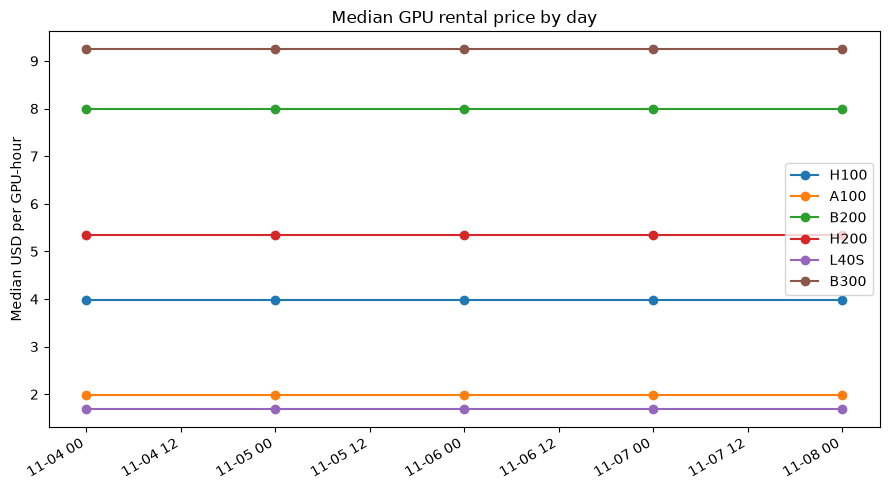

In [5]:
top = history.groupby('gpu').n_rows.max().sort_values(ascending=False).head(6).index
fig, ax = plt.subplots(figsize=(9, 5))
for g in top:
    h = history[history.gpu == g].sort_values('date')
    ax.plot(h.date, h.median_usd_per_gpu_hr, marker='o', label=g)
ax.set_ylabel('Median USD per GPU-hour'); ax.set_title('Median GPU rental price by day')
ax.legend(); fig.autofmt_xdate(); plt.tight_layout(); plt.show()

## 5. Provider price changes between snapshots

In [6]:
key = ['provider', 'gpu', 'variant', 'gpus_per_unit', 'price_type', 'term', 'region', 'billing_unit']
date_col = 'snapshot_date' if 'snapshot_date' in rows.columns else 'date'
r = rows.dropna(subset=['price_usd_per_gpu_hr']).copy()
for k in key:
    if k in r.columns: r[k] = r[k].astype(str).replace('nan', '')
k = [c for c in key if c in r.columns]
r = r.sort_values(date_col)
r['prev'] = r.groupby(k).price_usd_per_gpu_hr.shift()
chg = r[r.prev.notna() & (r.price_usd_per_gpu_hr != r.prev)].copy()
chg['pct'] = ((chg.price_usd_per_gpu_hr / chg.prev - 1) * 100).round(1)
print(len(chg), 'price changes')
chg[[date_col] + ['provider', 'gpu', 'variant', 'price_type'] + ['prev', 'price_usd_per_gpu_hr', 'pct']].sort_values('pct').head(25)

24 price changes


,snapshot_date,provider,gpu,variant,price_type,prev,price_usd_per_gpu_hr,pct
577,2026-11-06,Verda,A100,SXM4 40GB,on_demand,1.6410,1.6570,1.0
556,2026-11-06,Verda,B300,SXM6 268GB,spot,5.7850,5.8450,1.0
546,2026-11-06,Verda,B300,SXM6 268GB,on_demand,11.5700,11.6900,1.0
535,2026-11-06,Verda,B200,SXM6 180GB,spot,4.5240,4.5690,1.0
566,2026-11-06,Verda,GB300,SXM6 288GB,spot,6.6530,6.7220,1.0
564,2026-11-06,Verda,GB300,SXM6 288GB,on_demand,13.3100,13.4400,1.0
587,2026-11-06,Verda,A100,SXM4 80GB,on_demand,2.2930,2.3160,1.0
608,2026-11-06,Verda,A100,SXM4 80GB,spot,1.1470,1.1580,1.0
489,2026-11-06,Verda,H200,SXM5 141GB,on_demand,6.3760,6.4400,1.0
471,2026-11-06,Verda,H100,SXM5 80GB,spot,2.4450,2.4690,1.0


## Notes

- Public list prices only. Reserved and negotiated prices are often lower.
- `confidence` is high for API or itemized prices, medium for "starting at" prices, low otherwise.
- The dataset is updated as prices are re-checked. For live comparisons and calculators (GPU memory per model, self-host vs API cost), see the [compute desk](https://hundredthrun-compute-desk.pages.dev).

License: CC BY 4.0, credit "Hundredth Run compute desk".